In [25]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# Подвиг 5

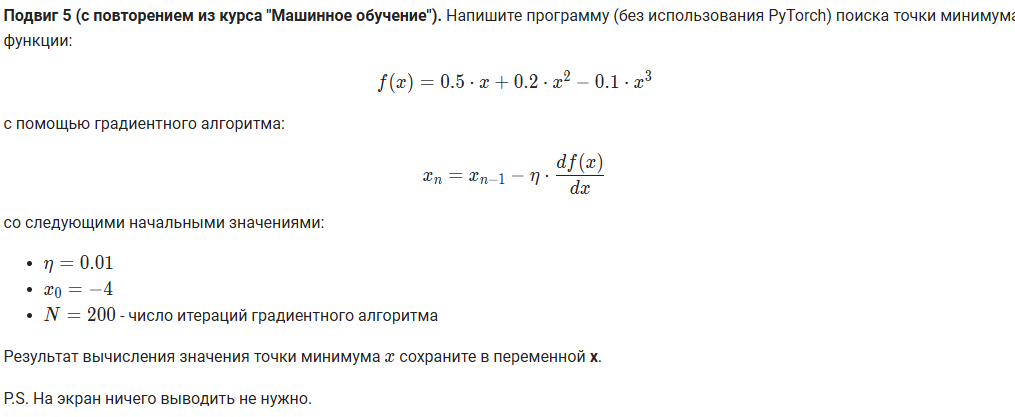

In [20]:
def func(x):
    return 0.5 * x + 0.2 * x ** 2 - 0.1 * x ** 3


def df(x):
    return  (0.5+0.4*x-0.3*x**2)# здесь выражение производной функции f(x)

x_iter = []
y_iter = []
lr = 0.01
x0 = -9
N = 2000
for i in range(N):
    x = x0 - lr*df(x0)
    x0 = x
    x_iter.append(x)
    y_iter.append(func(x))

xx = np.linspace(-10, 10, 1000)
yy = func(xx)
plt.plot(xx, yy)
plt.plot(x_iter, y_iter, linestyle='', marker='.', color='red')


# Подвиг 6 

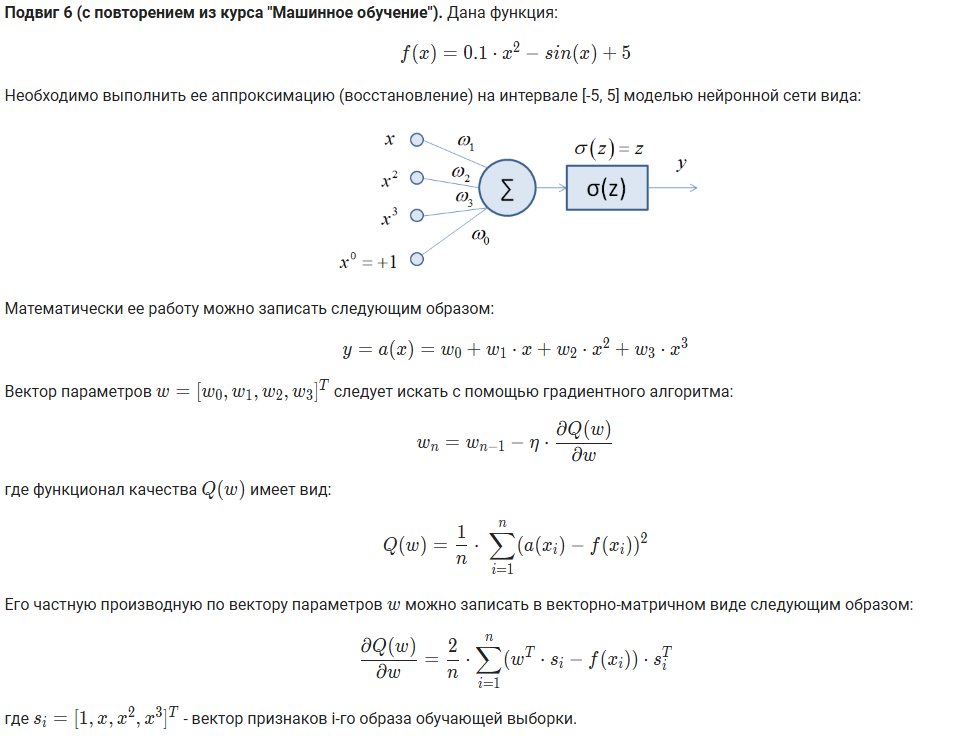

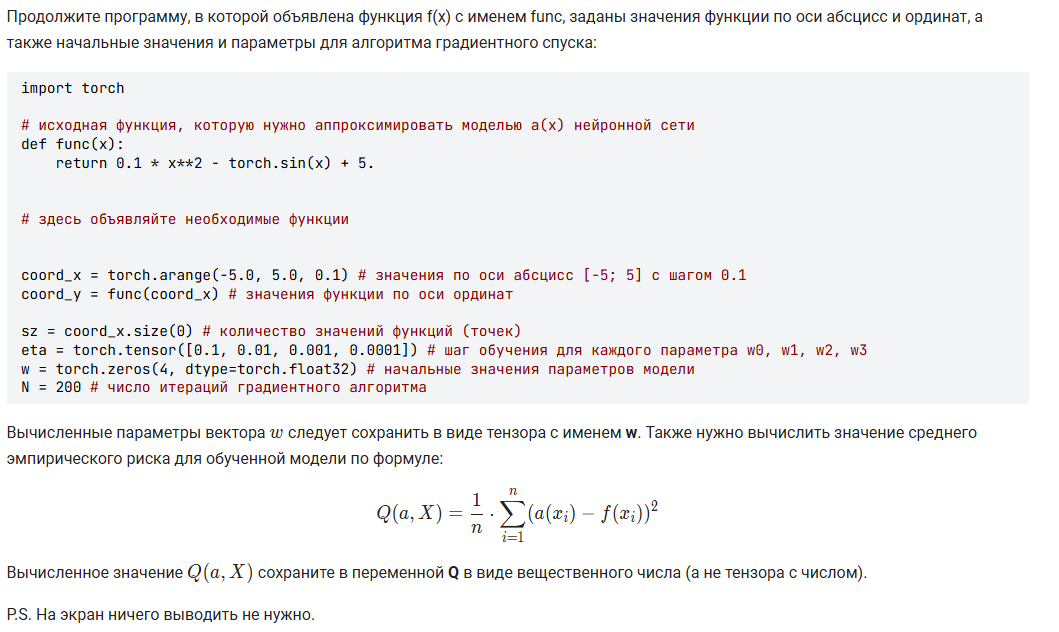

In [177]:
import torch

# исходная функция, которую нужно аппроксимировать моделью a(x) нейронной сети
def func(x):
    return 0.1 * x**2 - torch.sin(x) + 5

def model(w, x):
    return w[0] + w[1]*x + w[2]*x**2 + w[3]*x**3

# здесь объявляйте необходимые функции
def loss(w, x):
    return torch.sum((func(x)-model(w, x))**2) / x.shape[0]

def d_loss(w, x):
    channel = x.view(-1, 1)
    ones = torch.ones(x.shape[0], dtype=torch.float32).view(-1, 1) 
    batch = torch.cat([ones, channel, channel**2, channel**3], dim=1) # 100x4
    w = w.view(-1, 1) # 4x1
    pred = batch@w - func(x).view(-1, 1) # 100x1
    predT = pred.transpose(1, 0) # 1x100
    grad = predT@batch # 1x4
    grad = grad.squeeze() # (, 4)
    grad = 2*grad/x.shape[0]
    return grad

    
coord_x = torch.arange(-5.0, 5.0, 0.1) # значения по оси абсцисс [-5; 5] с шагом 0.1
coord_y = func(coord_x) # значения функции по оси ординат

sz = coord_x.size(0) # количество значений функций (точек)
eta = torch.tensor([0.1, 0.01, 0.001, 0.0001]) # шаг обучения для каждого параметра w0, w1, w2, w3
# eta = torch.tensor([0.001, 0.0001, 0.00001, 0.000001])
w0 = torch.zeros(4, dtype=torch.float32) # начальные значения параметров модели
N = 200 # число итераций градиентного алгоритма


for _ in range(N):
    w = w0 - eta*d_loss(w0, coord_x)
    Q = loss(w, coord_x).item()
    w0 = w
    print(w, Q)
Q

tensor([1.1648, 0.0020, 0.1079, 0.0019]) 14.625086784362793
tensor([1.9172, 0.0029, 0.1695, 0.0038]) 6.941818714141846
tensor([2.4170e+00, 1.1087e-03, 2.0326e-01, 5.4119e-03]) 3.950732469558716
tensor([ 2.7609, -0.0031,  0.2203,  0.0067]) 2.7109484672546387
tensor([ 3.0078, -0.0091,  0.2275,  0.0077]) 2.1335391998291016
tensor([ 3.1937, -0.0161,  0.2288,  0.0085]) 1.8139899969100952
tensor([ 3.3403, -0.0238,  0.2267,  0.0092]) 1.601165771484375
tensor([ 3.4612, -0.0318,  0.2227,  0.0098]) 1.4378819465637207
tensor([ 3.5646, -0.0399,  0.2177,  0.0103]) 1.3018745183944702
tensor([ 3.6557, -0.0480,  0.2123,  0.0108]) 1.1839323043823242
tensor([ 3.7377, -0.0561,  0.2067,  0.0113]) 1.0797829627990723
tensor([ 3.8127, -0.0640,  0.2011,  0.0117]) 0.987077534198761
tensor([ 3.8820, -0.0718,  0.1957,  0.0121]) 0.9042624831199646
tensor([ 3.9465, -0.0794,  0.1905,  0.0125]) 0.8301540613174438
tensor([ 4.0068, -0.0868,  0.1855,  0.0130]) 0.7637715339660645
tensor([ 4.0633, -0.0941,  0.1808,  0.01

0.13061460852622986

In [190]:
import torch

# исходная функция, которую нужно аппроксимировать моделью a(x) нейронной сети
def func(x):
    return 0.1 * x**2 - torch.sin(x) + 5

def model(w, x):
    return w[0] + w[1]*x + w[2]*x**2 + w[3]*x**3

# здесь объявляйте необходимые функции
def loss(w, x):
    return torch.sum((func(x)-model(w, x))**2) / x.shape[0]

def d_loss(w, x):
    # w = w # [4]
    # batch = torch.stack([torch.ones_like(x), x, x**2, x**3], dim=1) # 100x4
    # pred = batch@w - func(x)      # [100x4] @ [4] - [100] == [100] - [100]
    # grad = pred@batch             # 100 @ 100x4
    # grad = 2*grad/x.shape[0]

    w = w # [4]
    batch = torch.stack([torch.ones_like(x), x, x**2, x**3], dim=1).T # 4x100
    pred = w.T@batch - func(x)      # [100x4] @ [4] - [100] == [100] - [100]
    grad = pred@batch.T             # 100 @ 100x4
    grad = 2*grad/x.shape[0]
    return grad

    
coord_x = torch.arange(-5.0, 5.0, 0.1) # значения по оси абсцисс [-5; 5] с шагом 0.1
coord_y = func(coord_x) # значения функции по оси ординат

sz = coord_x.size(0) # количество значений функций (точек)
eta = torch.tensor([0.1, 0.01, 0.001, 0.0001]) # шаг обучения для каждого параметра w0, w1, w2, w3
w0 = torch.zeros(4, dtype=torch.float32) # начальные значения параметров модели
N = 200 # число итераций градиентного алгоритма


for _ in range(N):
    w = w0 - eta*d_loss(w0, coord_x)
    Q = loss(w, coord_x).item()
    w0 = w
    print(w, Q)
Q

tensor([1.1648, 0.0020, 0.1079, 0.0019]) 14.625086784362793
tensor([1.9172, 0.0029, 0.1695, 0.0038]) 6.941818714141846
tensor([2.4170e+00, 1.1087e-03, 2.0326e-01, 5.4119e-03]) 3.950732469558716
tensor([ 2.7609, -0.0031,  0.2203,  0.0067]) 2.7109484672546387
tensor([ 3.0078, -0.0091,  0.2275,  0.0077]) 2.1335391998291016
tensor([ 3.1937, -0.0161,  0.2288,  0.0085]) 1.8139899969100952
tensor([ 3.3403, -0.0238,  0.2267,  0.0092]) 1.601165771484375
tensor([ 3.4612, -0.0318,  0.2227,  0.0098]) 1.4378819465637207
tensor([ 3.5646, -0.0399,  0.2177,  0.0103]) 1.3018745183944702
tensor([ 3.6557, -0.0480,  0.2123,  0.0108]) 1.1839323043823242
tensor([ 3.7377, -0.0561,  0.2067,  0.0113]) 1.0797829627990723
tensor([ 3.8127, -0.0640,  0.2011,  0.0117]) 0.987077534198761
tensor([ 3.8820, -0.0718,  0.1957,  0.0121]) 0.9042624831199646
tensor([ 3.9465, -0.0794,  0.1905,  0.0125]) 0.8301540613174438
tensor([ 4.0068, -0.0868,  0.1855,  0.0130]) 0.7637715339660645
tensor([ 4.0633, -0.0941,  0.1808,  0.01

0.13061460852622986

In [179]:
coord_x.shape

torch.Size([100])

In [181]:
torch.tensor([1,2,3]).T

tensor([1, 2, 3])

In [151]:
model(w, coord_x)

IndexError: index 1 is out of bounds for dimension 0 with size 1

In [87]:
def model(w, x):
    return w[0] + w[1]*x + w[2]*x**2 + w[3]*x**3

def d_loss(w, x):
    channel = x.view(-1, 1)
    ones = torch.ones(x.shape[0], dtype=torch.float32).view(-1, 1)
    batch = torch.concat([ones, channel, channel**2, channel**3], dim=1)
    return (2/x.shape[0]) * torch.sum((w@batch.transpose(1, 0) - func(x))@batch)

w = torch.zeros(4, dtype=torch.float32)
coord_x = torch.arange(-5.0, 5.0, 0.1)

d_loss(w, coord_x)

tensor(-138.2433)

In [39]:
x = coord_x
ones = torch/net
torch.tensor([x, x**2, x**3], dtype=torch.float32).shape

ValueError: only one element tensors can be converted to Python scalars

In [41]:
torch.tensor([x, x**2, x**3])

ValueError: only one element tensors can be converted to Python scalars

In [45]:
torch.ones(x.shape[0])

tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [71]:
torch.tensor([1,2,3], dtype=torch.float32).transpose(1, 0)

IndexError: Dimension out of range (expected to be in range of [-1, 0], but got 1)

In [184]:
m = torch.arange(12).view(3, -1) # 3x4
v = torch.arange(3)              # 3

In [186]:
v@m

tensor([20, 23, 26, 29])

In [189]:
m.T@v

tensor([20, 23, 26, 29])